# 09 – Genre only: science fiction, fantasy or mystery/thriller

A focused summary of the genre experiments. **Nothing is retrained or re-validated here:** every table and figure is read from the results saved by notebooks 06 (classical models) and 07 (small neural network) in `report/ml/phase2/`, on the **saved grouped splits** (`split_genre.csv`, group = `ol_group`). Notebooks 06/07 and the datasets are unchanged. Only the demo at the end refits the already-selected models once.

**Task.** Predict the catalogue genre of a clearly single-genre book (exactly one genre flag): science fiction, fantasy or mystery/thriller (16,515 books). The labels come from subject tags, so the tags (and everything derived from them) are **never inputs**.

**Inputs.** *Without description:* title words, creators, publication year, scanned pages, archive age, number of creators and title length. *With description:* exactly the same plus the description text.

**Protocol (from 06/07).** 80 % of work groups form the training pool (5 grouped, stratified CV folds); 20 % are a locked test set. The best setting of each model was chosen by **CV macro-F1** before the test set was scored. Models: dummy baseline, LogisticRegression, LinearSVC, HistGradientBoosting (classical) and a small MLP (neural, three predeclared seeds averaged, grouped early stopping).

### Reopen tomorrow: saved models and results

Run the demo **Setup / Load** cell and then a book example. Completed fitted models and preprocessing are saved in `report/ml/models/` and loaded automatically after a kernel or VS Code restart. A missing or changed model is fitted and saved once. Keep that folder on this computer. Run All reuses existing experiment caches by default.

Set `RETRAIN = True` below only when you intentionally want to recompute training. Saving a notebook keeps its displayed outputs; a checkpoint saves the fitted model. Close VS Code after the training/save step finishes; unfinished training is not resumed automatically.

In [ ]:
RETRAIN = False  # False: reuse saved results/models; True: deliberately retrain


In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
notebook_dir = Path.cwd() if (Path.cwd() / "phase2_experiment.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(notebook_dir))
import phase2_experiment as p2
P = p2.OUT; FIG = P / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 70)
FAM = ["classical", "neural"]
need = [f"genre_{f}_{x}" for f in FAM for x in ("cv_summary.csv", "cv_selection.csv", "test_results.csv", "test_confusion.csv", "test_bootstrap.csv", "learning_curves.csv")] + ["split_genre.csv", "split_genre_meta.json"]
missing = [n for n in need if not (P / n).exists()]
assert not missing, f"run notebooks 06 and 07 first; missing {missing}"
meta = json.loads((P / "split_genre_meta.json").read_text(encoding="utf-8"))
assert meta["sha256"] == p2.sha256_file(P / "split_genre.csv"), "the saved genre split changed"
print("saved genre split verified:", {k: meta[k] for k in ("rows", "groups", "pool_rows", "test_rows", "cv_folds")})

saved genre split verified: {'rows': 16515, 'groups': 15555, 'pool_rows': 13226, 'test_rows': 3289, 'cv_folds': 5}


## 1. The data behind the saved results

In [2]:
df = p2.load_cohort(); dg = p2.task_frame(df, "genre")
man = pd.read_csv(P / "split_genre.csv", keep_default_na=False)
m = man.assign(genre=[p2.GENRES[i] for i in man.y])
print(pd.crosstab(m.split, m.genre, margins=True).to_string())
print(f"\ngenre flags per book in the full cohort: {df[['genre_science_fiction','genre_fantasy','genre_mystery_thriller']].sum(1).value_counts().sort_index().to_dict()} -> only the 1-flag books are used")
print("model inputs:", p2.ALLOWED_COLS); print("never inputs:", p2.EXCLUDED)

genre  fantasy  mystery_thriller  science_fiction    All
split                                                   
pool      4710              4688             3828  13226
test      1178              1191              920   3289
All       5888              5879             4748  16515

genre flags per book in the full cohort: {0: 40, 1: 16515, 2: 1127, 3: 45} -> only the 1-flag books are used
model inputs: ['publication_year', 'log_pages', 'age_years', 'n_creators', 'title_words', 'title_text', 'creator_tokens', 'description']
never inputs: ['subjects', 'n_subjects', 'juvenile', 'genre_primary', 'genre_science_fiction', 'genre_fantasy', 'genre_mystery_thriller', 'sampling_stratum', 'in_americana', 'source_batch', 'identifier', 'ol_group', 'work_group', 'views_all_time', 'description_words']


## 2. Cross-validation (read from 06/07): best setting of each model on the training pool

In [3]:
sel = {f: pd.read_csv(P / f"genre_{f}_cv_selection.csv") for f in FAM}
cvt = pd.concat([sel[f].assign(family_nb=("06 classical" if f == "classical" else "07 neural")) for f in FAM])
cvt["model"] = cvt.algo.map({"dummy": "dummy baseline", "logreg": "LogisticRegression", "linsvc": "LinearSVC", "hgb": "HistGradientBoosting", "mlp": "MLP (neural)"})
cvt["variant"] = cvt.variant.map({"A": "without description", "B": "with description"})
tab = cvt.pivot(index="model", columns="variant", values=["cv_macro_f1", "cv_accuracy"]).round(3).reindex(["dummy baseline", "LogisticRegression", "LinearSVC", "HistGradientBoosting", "MLP (neural)"])
print("Mean over 5 grouped CV folds (training pool only)"); display(tab)
display(cvt[cvt.algo != "dummy"][["model", "variant", "cfg"]].sort_values(["model", "variant"]).reset_index(drop=True))

Mean over 5 grouped CV folds (training pool only)


cv_macro_f1                          cv_accuracy                    
variant              with description without description with description without description
model                                                                                         
dummy baseline                  0.172               0.172            0.349               0.349
LogisticRegression              0.851               0.687            0.854               0.691
LinearSVC                       0.851               0.686            0.854               0.691
HistGradientBoosting            0.807               0.630            0.811               0.635
MLP (neural)                    0.823               0.620            0.826               0.624

,model,variant,cfg
0,HistGradientBoosting,with description,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6, ""min_samp..."
1,HistGradientBoosting,without description,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6, ""min_samp..."
2,LinearSVC,with description,"{""C"": 0.3}"
3,LinearSVC,without description,"{""C"": 0.1}"
4,LogisticRegression,with description,"{""C"": 1.0}"
5,LogisticRegression,without description,"{""C"": 1.0}"
6,MLP (neural),with description,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}"
7,MLP (neural),without description,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}"


## 3. Locked test set (read from 06/07)

In [4]:
res = pd.concat([pd.read_csv(P / f"genre_{f}_test_results.csv") for f in FAM]).drop_duplicates(["variant", "algo"])
res["model"] = res.algo.map({"dummy": "dummy baseline", "logreg": "LogisticRegression", "linsvc": "LinearSVC", "hgb": "HistGradientBoosting", "mlp": "MLP (neural)"})
res["variant"] = res.variant.map({"A": "without description", "B": "with description"})
order = ["dummy baseline", "LogisticRegression", "LinearSVC", "HistGradientBoosting", "MLP (neural)"]
T = res.pivot(index="model", columns="variant", values=["accuracy", "macro_f1"]).reindex(order); T["description gain (accuracy)"] = T[("accuracy", "with description")] - T[("accuracy", "without description")]
print("TEST SET: 3,289 books (920 science fiction / 1,178 fantasy / 1,191 mystery-thriller)"); display(T.round(4))
pc = res.pivot(index="model", columns="variant", values=["f1_science_fiction", "f1_fantasy", "f1_mystery_thriller"]).reindex(order); print("F1 per genre"); display(pc.round(3))
res.drop(columns=["cfg"], errors="ignore").round(5).to_csv(P / "genre_only_test_summary.csv", index=False)

TEST SET: 3,289 books (920 science fiction / 1,178 fantasy / 1,191 mystery-thriller)


accuracy                             macro_f1                     description gain (accuracy)
variant              with description without description with description without description                            
model                                                                                                                     
dummy baseline                 0.3582              0.3582           0.1758              0.1758                      0.0000
LogisticRegression             0.8614              0.7078           0.8581              0.7020                      0.1535
LinearSVC                      0.8626              0.7084           0.8595              0.7027                      0.1541
HistGradientBoosting           0.8042              0.6254           0.7990              0.6198                      0.1788
MLP (neural)                   0.8121              0.6120           0.8065              0.6043                      0.2001

F1 per genre


f1_science_fiction                           f1_fantasy                     f1_mystery_thriller                    
variant                with description without description with description without description    with description without description
model                                                                                                                                   
dummy baseline                    0.000               0.000            0.527               0.527               0.000               0.000
LogisticRegression                0.824               0.653            0.848               0.712               0.903               0.742
LinearSVC                         0.827               0.656            0.851               0.712               0.900               0.741
HistGradientBoosting              0.747               0.573            0.792               0.607               0.858               0.679
MLP (neural)                      0.752               0.538            0.796               0.610               0.872               0.665

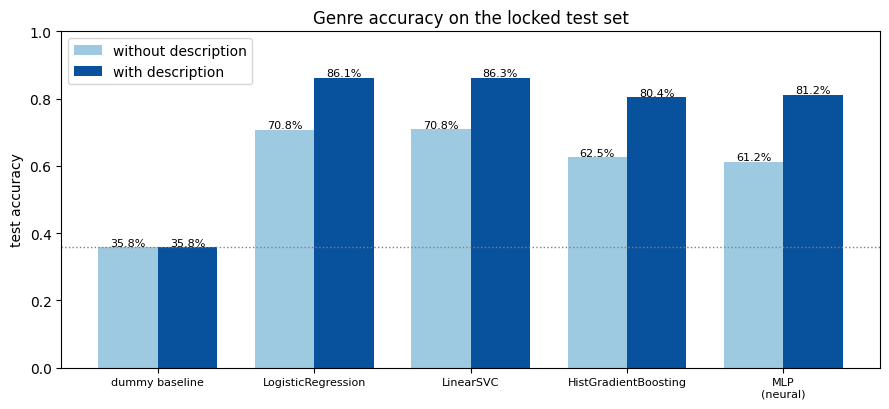

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2)); w = .38; x = np.arange(len(order))
for j, (v, c) in enumerate((("without description", "#9ecae1"), ("with description", "#08519c"))):
    vals = [float(res[(res.model == mo) & (res.variant == v)].accuracy.iloc[0]) for mo in order]
    ax.bar(x + (j - .5) * w, vals, w, color=c, label=v)
    for xi, val in zip(x + (j - .5) * w, vals): ax.text(xi, val + .005, f"{val:.1%}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([o.replace(" (neural)", "\n(neural)").replace("Histogram", "") for o in order], fontsize=8); ax.set(ylabel="test accuracy", ylim=(0, 1), title="Genre accuracy on the locked test set"); ax.axhline(.358, color="grey", ls=":", lw=1); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "genre_only_accuracy.png", dpi=130); plt.show()

### Confusion matrices (best classical model chosen by CV, and the neural network)

best classical model by CV: {'A': 'logreg', 'B': 'linsvc'}


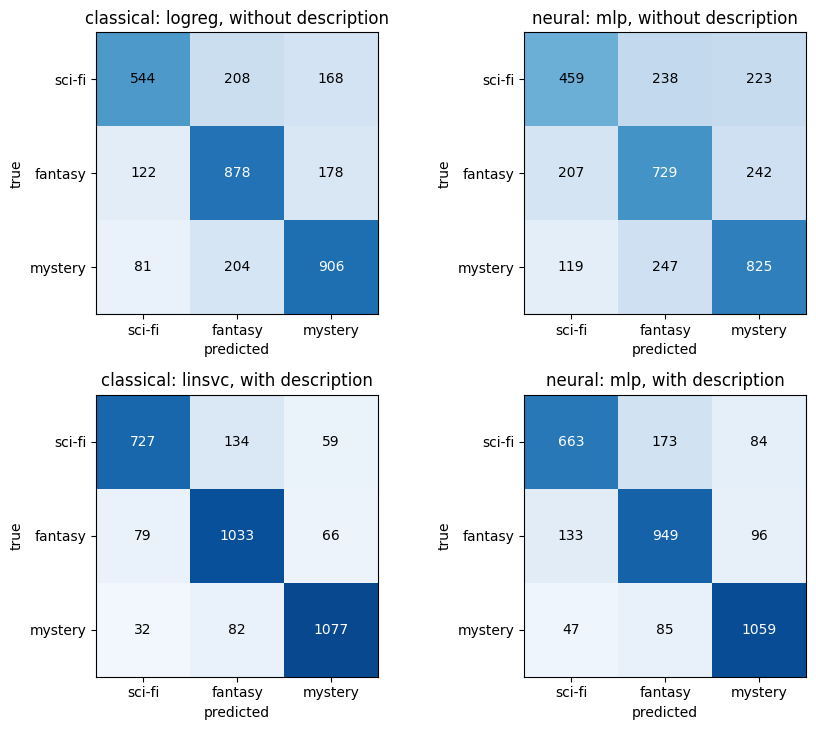

In [6]:
cm = pd.concat([pd.read_csv(P / f"genre_{f}_test_confusion.csv") for f in FAM]).drop_duplicates(["variant", "algo", "true_class"])
best_cl = {v: sel["classical"][(sel["classical"].variant == v) & sel["classical"].algo.isin(["logreg", "linsvc", "hgb"])].sort_values("cv_macro_f1", ascending=False).iloc[0].algo for v in "AB"}
print("best classical model by CV:", best_cl)
fig, ax = plt.subplots(2, 2, figsize=(9, 7.4)); cls = p2.GENRES
for i, v in enumerate("AB"):
    for j, (name, a) in enumerate((("classical: " + best_cl[v], best_cl[v]), ("neural: mlp", "mlp"))):
        x = cm[(cm.variant == v) & (cm.algo == a)].set_index("true_class").loc[cls][[f"pred_{c}" for c in cls]].to_numpy()
        ax[i, j].imshow(x / x.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for p in range(3):
            for q in range(3): ax[i, j].text(q, p, str(x[p, q]), ha="center", va="center", color="black" if x[p, q] / x[p].sum() < .6 else "white")
        ax[i, j].set(xticks=range(3), yticks=range(3), xticklabels=["sci-fi", "fantasy", "mystery"], yticklabels=["sci-fi", "fantasy", "mystery"], title=f"{name}, {'without' if v == 'A' else 'with'} description", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.savefig(FIG / "genre_only_confusion.png", dpi=130); plt.show()

## 4. Are the differences reliable? (group-bootstrap intervals saved by 06/07)

In [7]:
bc = pd.read_csv(P / "genre_classical_test_bootstrap.csv"); bn = pd.read_csv(P / "genre_neural_test_bootstrap.csv")
keep = ["comparison", "detail", "accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95"]
print("Classical models (second minus first; intervals that include 0 are not distinguishable from noise)"); display(bc[bc.comparison.str.startswith(("description", "CV-selected"))][keep].round(3))
print("Neural network"); display(bn[bn.comparison.str.startswith(("description", "neural network minus best classical"))][keep].round(3))

Classical models (second minus first; intervals that include 0 are not distinguishable from noise)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95
0,"description effect (B - A), same algorithm",dummy,0.000,0.000,0.000,0.000,0.000,0.000
1,"description effect (B - A), same algorithm",hgb,0.179,0.160,0.198,0.179,0.160,0.199
2,"description effect (B - A), same algorithm",linsvc,0.154,0.138,0.169,0.156,0.140,0.172
3,"description effect (B - A), same algorithm",logreg,0.153,0.138,0.169,0.156,0.140,0.172
4,CV-selected best classical model (B winner - A winner),linsvc (B) vs logreg (A),0.154,0.139,0.170,0.157,0.142,0.172


Neural network


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95
0,"description effect (B - A), neural network",mlp,0.200,0.182,0.219,0.202,0.184,0.222
1,"neural network minus best classical model chosen by CV, variant A",mlp - logreg,-0.096,-0.113,-0.080,-0.098,-0.115,-0.082
3,"neural network minus best classical model chosen by CV, variant B",mlp - linsvc,-0.050,-0.063,-0.038,-0.053,-0.066,-0.040


## 5. Does the result depend on author names? (from 06/07)

In [8]:
au = res[res.algo != "dummy"].copy(); ccols = [c for c in au.columns if "|" in c]
au = au[["model", "variant", "accuracy"] + ccols].rename(columns=lambda c: c.replace("accuracy | ", "acc, ").replace("macro_f1 | ", "F1, "))
print("Accuracy on test books whose creator also appears in the training pool (1,823) versus creators never seen in training (1,466)"); display(au.round(3))
oc = pd.read_csv(P / "outside_random_check.csv"); print("Extra check on 400 random archive.org books in none of our datasets (genre accuracy):"); display(oc[["family", "description", "genre_accuracy", "n_books"]])

Accuracy on test books whose creator also appears in the training pool (1,823) versus creators never seen in training (1,466)


,model,variant,accuracy,"acc, author seen in training","F1, author seen in training","acc, author NOT seen in training","F1, author NOT seen in training"
1,HistGradientBoosting,without description,0.625,0.675,0.673,0.564,0.549
2,LinearSVC,without description,0.708,0.797,0.796,0.598,0.574
3,LogisticRegression,without description,0.708,0.798,0.796,0.596,0.573
5,HistGradientBoosting,with description,0.804,0.826,0.824,0.778,0.763
6,LinearSVC,with description,0.863,0.897,0.897,0.819,0.809
7,LogisticRegression,with description,0.861,0.895,0.894,0.820,0.809
0,MLP (neural),without description,0.612,0.662,0.658,0.550,0.532
1,MLP (neural),with description,0.812,0.833,0.832,0.786,0.770


Extra check on 400 random archive.org books in none of our datasets (genre accuracy):


,family,description,genre_accuracy,n_books
0,classical,without,0.760,400
1,classical,with,0.885,400
2,neural,without,0.640,400
3,neural,with,0.840,400


## 6. Learning curves and training time (from 06/07)

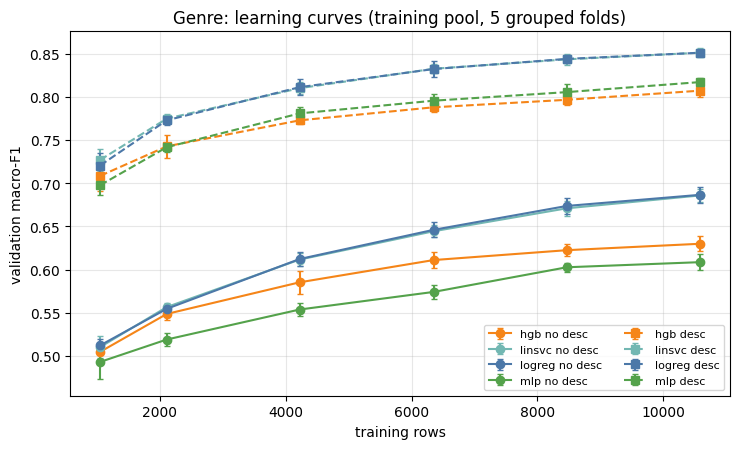

Training time (seconds; MLP time in the per-fold column is the sum of three seeds; CPU only)


,algo,variant,task,cv_fit_s_per_fold,cv_fit_s_per_seed_or_model,final_fit_s_on_pool
2,hgb,A,genre,7.28,7.28,3.88
3,hgb,B,genre,26.60,26.60,13.87
4,linsvc,A,genre,0.13,0.13,0.16
5,linsvc,B,genre,17.04,17.04,13.62
6,logreg,A,genre,0.87,0.87,0.87
7,logreg,B,genre,1.99,1.99,2.10
0,mlp,A,genre,18.51,6.17,22.48
1,mlp,B,genre,7.51,2.50,7.59


In [9]:
lc = pd.concat([pd.read_csv(P / f"genre_{f}_learning_curves.csv") for f in FAM]); col = {"logreg": "#4c78a8", "linsvc": "#72b7b2", "hgb": "#f58518", "mlp": "#54a24b"}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for (v, a), g in lc.groupby(["variant", "algo"]):
    s = g.groupby("fraction").agg(rows=("train_rows", "mean"), m=("macro_f1", "mean"), sd=("macro_f1", "std"))
    ax.errorbar(s.rows, s.m, yerr=s.sd, color=col[a], ls="-" if v == "A" else "--", marker="o" if v == "A" else "s", capsize=2, label=f"{a} {'no desc' if v == 'A' else 'desc'}")
ax.set(xlabel="training rows", ylabel="validation macro-F1", title="Genre: learning curves (training pool, 5 grouped folds)"); ax.legend(ncol=2, fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "genre_only_learning_curves.png", dpi=130); plt.show()
tt = pd.concat([pd.read_csv(P / f"training_times_{f}.csv") for f in FAM]); tt = tt[(tt.task == "genre") & (tt.algo != "dummy")]
print("Training time (seconds; MLP time in the per-fold column is the sum of three seeds; CPU only)"); display(tt.round(2))

## 7. Findings

All figures are read from the results saved by notebooks 06 and 07 (same grouped splits; locked test set of 3,289 books; nothing was re-run for this notebook).

| Test set (3,289 books) | Without description: accuracy / macro-F1 | With description: accuracy / macro-F1 |
|---|---|---|
| Dummy baseline (always the commonest training genre) | 35.8 % / 0.176 | 35.8 % / 0.176 |
| LogisticRegression | 70.8 % / 0.702 | 86.1 % / 0.858 |
| **LinearSVC** | **70.8 % / 0.703** | **86.3 % / 0.860** |
| HistGradientBoosting | 62.5 % / 0.620 | 80.4 % / 0.799 |
| MLP (small neural network) | 61.2 % / 0.604 | 81.2 % / 0.807 |

**Which model performed best?** The **linear models on sparse text features, with the description**: LinearSVC 86.3 % (macro-F1 0.860) and LogisticRegression 86.1 % (0.858). They are statistically indistinguishable (identical CV macro-F1 of 0.851; test difference 0.1 point), and LinearSVC was the one cross-validation picked by tie-break. LogisticRegression is about as accurate, faster to fit (about 2 s versus 14 s on the full pool) and gives real probabilities. Without a description the same two linear models are again best (70.8 %).

**Do descriptions help? Yes, strongly, for every model.** Accuracy rises by 15.4 points for LogisticRegression and LinearSVC (group-bootstrap 95 % interval +13.9 to +17.0 for the CV-chosen pair), 17.9 for HistGradientBoosting and 20.0 for the neural network (+18.2 to +21.9). Both variants use exactly the same books and folds.

**Does the neural network help? No.** Neural minus the best classical model chosen by CV: **−9.6 accuracy points without description** (−11.3 to −8.0) and **−5.0 with description** (−6.3 to −3.8). In cross-validation the MLP did edge out HistGradientBoosting with descriptions (macro-F1 0.823 versus 0.807), but both are well below the linear models (0.851). The three neural seeds agree closely (see 07), so this is not a bad-seed effect. The network sees only compressed (SVD) text features and stops after very few epochs; a larger search or a pretrained text model was not tried.

**Per genre.** Mystery/thriller is the easiest (F1 0.90 for the best models with description), fantasy next (0.85), science fiction the hardest (0.83); without description science fiction drops to 0.65.

**How much is author memory?** Without description, accuracy is 79.8 % when the book's creator also appears in the training pool and 59.6 % for unseen creators (LogisticRegression), so part of the metadata-only score is author recognition. With description the gap shrinks (89.7 % versus 81.9 % for LinearSVC). An ad-hoc check on 400 random archive.org books in none of our datasets gave 76.0 % / 88.5 % (classical, without / with description) and 64.0 % / 84.0 % (neural), consistent with the test set.

**Learning curves.** With the description, macro-F1 climbs from 0.72 (10 % of the training pool) to 0.85 for the linear models and is still creeping up (0.844 to 0.851 over the last 20 %); the neural network goes from 0.70 to 0.82. Without description the linear models rise from 0.51 to 0.69. More data may help genre a little but cannot be promised to.

**Limits.**
* The labels are catalogue labels derived from subject tags, not a reader's verdict; some books (the trivia book in the first example) carry a genre that is not that of a novel.
* Only three genres: a romance or a history book would still be forced into one of them.
* The books are English archive.org books from 1840-2020. Nothing was tested on unpublished books, and `pages` and `archive_years` have no meaning for a new book (the demo substitutes training medians if they are left empty).
* One locked test set and one 400-book ad-hoc check: intervals ignore the choice of split.

## 8. Try it: one training book and one unseen book
Run **Setup** once: it refits only the **already-selected** genre models (the settings chosen by CV in 06/07) on the saved training pool of the genre task: no cross-validation, no test scoring, no change to any file. Then run the two examples. Each shows the prediction of the classical model and of the neural network **without** and **with** the description, with the catalogue genre beside them (the catalogue genre is never a model input). Edit `BOOK` to try your own book; leave `description` empty to see only the without-description rows. `archive_years` is the time the item has been on archive.org; entered values replace the training medians used when a field is left as `None`.

Both books were drawn by a **seeded random draw** (seed 2031), not hand-picked, so they may be unremarkable or hard: the training book is in the genre training pool; the unseen book is an archive.org book that is in none of our datasets (details from the saved 22 Nov 2026 catalogue snapshot).

In [2]:
# self-contained: this cell also works if it is the first cell you run
import sys, time
from pathlib import Path
import pandas as pd
from IPython.display import display
notebook_dir = Path.cwd() if (Path.cwd() / "phase2_experiment.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(notebook_dir))
import phase2_experiment as p2
import phase2_demo
t0 = time.time()
pred_classical = phase2_demo.Phase2Predictor.from_project("classical", verbose=False, tasks=("genre",), retrain=globals().get("RETRAIN", False))
pred_neural = phase2_demo.Phase2Predictor.from_project("neural", verbose=False, tasks=("genre",), retrain=globals().get("RETRAIN", False))
print(f"selected genre models ready in {time.time() - t0:.0f} s")
GL = phase2_demo.GENRE_LABELS

def show_genre(BOOK, CATALOGUE=None):
    frame, notes = pred_classical.prepare(**BOOK)
    variants = ["A"] + (["B"] if frame.description.iloc[0] else [])
    rows = []
    for v in variants:
        row = {"Inputs": "Without description" if v == "A" else "With description"}
        for name, P_ in (("Classical", pred_classical), ("Neural", pred_neural)):
            sc, kind = P_._scores("genre", v, frame); i = int(sc[0].argmax())
            row[f"{name} prediction"] = GL[p2.GENRES[i]]; row[f"{name} confidence (%)"] = round(float(sc[0][i]) * 100, 1)
        if CATALOGUE:
            row["Catalogue genre"] = GL[CATALOGUE]; row["Classical matches?"] = row["Classical prediction"] == GL[CATALOGUE]; row["Neural matches?"] = row["Neural prediction"] == GL[CATALOGUE]
        rows.append(row)
    print("Book:", BOOK["title"], "|", BOOK.get("author", "")); display(pd.DataFrame(rows))
    print("(confidence = model probability; for the classical with-description model, LinearSVC, it is a relative score and not a calibrated probability)")
    if len(notes): print("Missing details / assumptions used:"); display(notes)

selected genre models ready in 63 s


### 8.1 Training book (in the training pool) — *The Potter pensieve : trivial delights from the world of Har*
Catalogue genre: **fantasy** (from its subject tags; this is a trivia book about the Harry Potter world, which shows that the catalogue genre is a tag-based label and not always a novel's genre). Source: <https://archive.org/details/potterpensievetr0000farr>.

In [3]:
BOOK = {'title': 'The Potter pensieve : trivial delights from the world of Harry Potter',
 'description': 'For millions of Harry Potter fans around the world, reading (or re-reading) the latest novel or watching the latest film '
                'leaves them wanting more - more stories, more characters, more facts, more information about the young wizard, the world '
                'he inhabits, and the person who created it. With The Potter Pensieve, all of those questions can finally be answered "Not '
                'approved or endorsed by JK Rowling or Warner Bros."--Dustjacket Includes index',
 'author': 'Farrington, Karen',
 'publication_year': 2010,
 'pages': 200,
 'archive_years': 5.95}
CATALOGUE = 'fantasy'   # catalogue genre: shown beside the predictions, never used as an input
show_genre(BOOK, CATALOGUE)

Book: The Potter pensieve : trivial delights from the world of Harry Potter | Farrington, Karen


,Inputs,Classical prediction,Classical confidence (%),Neural prediction,Neural confidence (%),Catalogue genre,Classical matches?,Neural matches?
0,Without description,fantasy,69.1,fantasy,74.7,fantasy,True,True
1,With description,fantasy,63.9,fantasy,74.4,fantasy,True,True


(confidence = model probability; for the classical with-description model, LinearSVC, it is a relative score and not a calibrated probability)


### 8.2 Unseen book (in none of our datasets) — *The mystery of the missing microchips*
Catalogue genre: **mystery / thriller**. Source: <https://archive.org/details/mysteryofmissing00bibe>.

In [4]:
BOOK = {'title': 'The mystery of the missing microchips',
 'description': "When Carlos and the others don't show up for ice cream, Julie and Emily start looking for them. Soon they find their "
                'friends abandoned bicycles and several small computer chips. When a strange man with a red beard show up, wanting to know '
                'everything about the chips, the mystery deepens',
 'author': 'Bibee, John',
 'publication_year': 1995,
 'pages': 134,
 'archive_years': 16.22}
CATALOGUE = 'mystery_thriller'   # catalogue genre: shown beside the predictions, never used as an input
show_genre(BOOK, CATALOGUE)

Book: The mystery of the missing microchips | Bibee, John


,Inputs,Classical prediction,Classical confidence (%),Neural prediction,Neural confidence (%),Catalogue genre,Classical matches?,Neural matches?
0,Without description,mystery / thriller,93.5,mystery / thriller,98.5,mystery / thriller,True,True
1,With description,mystery / thriller,78.1,mystery / thriller,99.8,mystery / thriller,True,True


(confidence = model probability; for the classical with-description model, LinearSVC, it is a relative score and not a calibrated probability)
